# Oversampling

### <i> SDV using the `Condition` method.

<i> This is really useful for when you have rare, under-represented cases. Instead of creating thousands of rows, hoping to get that ONE row with the values you want, you can force SDV to create rows that meet this condition.

In [110]:
# Imports
from sdv.single_table import CTGANSynthesizer
from sdv.single_table import GaussianCopulaSynthesizer
from sdv.metadata import Metadata
from sdv.sampling import Condition
import pandas as pd
import seaborn as sns


# load data
df = pd.read_csv("../../lifestyle_sustainability_data.csv")

df.columns

Index(['ParticipantID', 'Age', 'Location', 'DietType', 'LocalFoodFrequency',
       'TransportationMode', 'EnergySource', 'HomeType', 'HomeSize',
       'ClothingFrequency', 'SustainableBrands', 'EnvironmentalAwareness',
       'CommunityInvolvement', 'MonthlyElectricityConsumption',
       'MonthlyWaterConsumption', 'Gender', 'UsingPlasticProducts',
       'DisposalMethods', 'PhysicalActivities', 'Rating'],
      dtype='object')

In [111]:
# to simplify this example, let's filter only some of the variables
df = df[['Age', 'HomeSize', 'EnvironmentalAwareness', 'MonthlyElectricityConsumption', 'MonthlyWaterConsumption', 'DisposalMethods', 'SustainableBrands',  'Gender', 'Rating']]

In [112]:
df

,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,DisposalMethods,SustainableBrands,Gender,Rating
0,35,800,5,100,1500,Composting,True,Female,5
1,28,1500,4,250,3000,Recycling,True,Male,4
2,65,2500,2,400,4500,Landfill,False,Male,1
3,42,950,4,150,2000,Recycling,True,Female,5
4,31,1800,3,300,3500,Combination,True,Non-Binary,3
...,...,...,...,...,...,...,...,...,...
494,38,1789,4,150,2000,Recycling,True,Female,4
495,25,987,2,400,4500,Landfill,False,Male,2
496,51,1678,5,280,3200,Recycling,True,Non-Binary,5
497,32,1850,1,397,4076,Recycling,False,Female,5


---

### SDV Condition

In [113]:
df.columns

Index(['Age', 'HomeSize', 'EnvironmentalAwareness',
       'MonthlyElectricityConsumption', 'MonthlyWaterConsumption',
       'DisposalMethods', 'SustainableBrands', 'Gender', 'Rating'],
      dtype='object')

In [114]:
# Let's let SDV metadata figure out what each column is containing.
metadata = Metadata.detect_from_dataframe(
    data=df
)

#   Landfill, SustainableBrands and Male

# You can set conditions here to generate more rows for. In this case, I want 10 more values of this data.
# I want CHAS and RAD to contain the 1 value.
condition = Condition(
    num_rows=50,
    column_values={
       # "Rating": 2,
       "DisposalMethods": "Landfill",
       "SustainableBrands": True,
       "Gender": "Male"
    }

)

# Set the synthetsizer and fit
synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit(df)

# Extract synthesized data from those specific conditions
synthetic_data = synthesizer.sample_from_conditions(
    conditions=[condition]
)

# Output dataframe
synthetic_data

c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\sdv\single_table\base.py:139: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
Sampling conditions: 100%|██████████| 50/50 [00:00<00:00, 915.34it/s]


,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,DisposalMethods,SustainableBrands,Gender,Rating
0,48,2554,3,206,3875,Landfill,True,Male,5
1,55,1806,4,70,3244,Landfill,True,Male,1
2,52,1300,1,254,2905,Landfill,True,Male,4
3,52,1038,5,273,3451,Landfill,True,Male,3
4,72,1721,1,441,3479,Landfill,True,Male,3
5,28,1585,4,78,3097,Landfill,True,Male,5
6,26,1017,4,323,1773,Landfill,True,Male,5
7,62,2233,2,113,2168,Landfill,True,Male,5
8,37,1367,4,157,2305,Landfill,True,Male,5
9,57,1101,5,79,2716,Landfill,True,Male,5


---

### Concatenating the original with the synthetic data

In [ ]:
# And this is how we combine the synthetic with the real dataset.
df_combined = pd.concat([df, synthetic_data])


In [117]:
df.query("SustainableBrands == True and DisposalMethods == 'Landfill' and Gender == 'Male'")

,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,DisposalMethods,SustainableBrands,Gender,Rating
255,50,1522,2,335,3749,Landfill,True,Male,2


In [118]:
df_combined.query("SustainableBrands == True and DisposalMethods == 'Landfill' and Gender == 'Male'")

,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,DisposalMethods,SustainableBrands,Gender,Rating
255,50,1522,2,335,3749,Landfill,True,Male,2
0,48,2554,3,206,3875,Landfill,True,Male,5
1,55,1806,4,70,3244,Landfill,True,Male,1
2,52,1300,1,254,2905,Landfill,True,Male,4
3,52,1038,5,273,3451,Landfill,True,Male,3
4,72,1721,1,441,3479,Landfill,True,Male,3
5,28,1585,4,78,3097,Landfill,True,Male,5
6,26,1017,4,323,1773,Landfill,True,Male,5
7,62,2233,2,113,2168,Landfill,True,Male,5
8,37,1367,4,157,2305,Landfill,True,Male,5


In [119]:
df['Rating'].value_counts()

Rating
5    176
3    101
1     97
4     91
2     34
Name: count, dtype: int64

In [120]:
df_combined['Rating'].value_counts()

Rating
5    207
3    106
1    102
4     97
2     37
Name: count, dtype: int64

<Axes: >

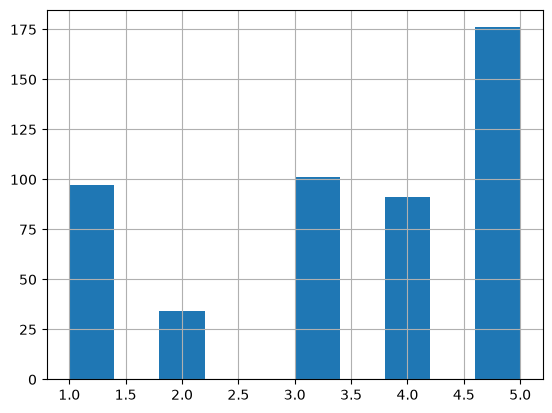

In [121]:
df['Rating'].hist()

<Axes: >

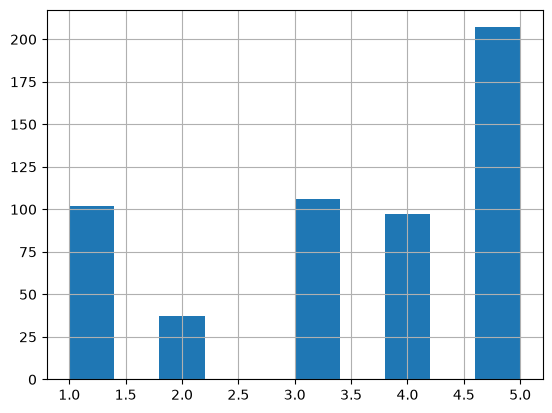

In [122]:
df_combined['Rating'].hist()

In [123]:
df.describe()

,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,Rating
count,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000
mean,44.052104,1518.046092,3.062124,291.963928,3139.521042,3.430862
std,14.904828,672.212235,1.342145,120.482275,1224.609306,1.502585
min,18.000000,407.000000,1.000000,55.000000,536.000000,1.000000
25%,31.000000,951.500000,2.000000,185.000000,2000.000000,2.000000
50%,44.000000,1450.000000,3.000000,295.000000,3350.000000,4.000000
75%,58.000000,1995.000000,4.000000,400.000000,4100.000000,5.000000
max,96.000000,2997.000000,5.000000,498.000000,5250.000000,5.000000


In [124]:
df_combined.describe()

,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,Rating
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,44.209472,1524.449909,3.096539,285.459016,3083.169399,3.491803
std,14.953267,670.023962,1.349428,122.994943,1225.885261,1.502561
min,18.000000,407.000000,1.000000,55.000000,536.000000,1.000000
25%,31.000000,960.000000,2.000000,178.000000,2000.000000,2.000000
50%,44.000000,1459.000000,3.000000,292.000000,3200.000000,4.000000
75%,58.000000,1996.000000,4.000000,395.000000,4055.000000,5.000000
max,96.000000,2997.000000,5.000000,498.000000,5250.000000,5.000000
